# Time Series Forecasting & Transfer Learning

---

## Table of Contents

### 1. Introduction

### 2. Project Objectives

### 3. Dataset Description
#### 3.1 Climate Dataset
#### 3.2 Intel Image Classification Dataset

### 4. Methodology
#### 4.1 Time Series Forecasting Workflow
#### 4.2 Transfer Learning Workflow

### 5. Part I: Time Series Forecasting

#### 5.1 Import Required Libraries

#### 5.2 Data Loading

#### 5.3 Data Understanding

#### 5.4 Data Preprocessing

#### 5.5 Missing Value Analysis

#### 5.6 Exploratory Data Analysis (EDA)

#### 5.7 Data Visualization

#### 5.8 Stationarity Testing

#### 5.9 ARIMA Model Implementation

#### 5.10 ARIMA Forecasting Results

#### 5.11 SARIMA Model Implementation

#### 5.12 SARIMA Forecasting Results

#### 5.13 Prophet Model Implementation

#### 5.14 Prophet Forecasting Results

#### 5.15 Model Evaluation

#### 5.16 Model Comparison

#### 5.17 Model Improvement

---

### 6. Part II: Transfer Learning

#### 6.1 Import Required Libraries

#### 6.2 Image Dataset Loading

#### 6.3 Image Preprocessing

#### 6.4 Data Augmentation

#### 6.5 MobileNetV2 Architecture

#### 6.6 Freezing Base Layers

#### 6.7 Adding Custom Classification Layers

#### 6.8 Model Compilation

#### 6.9 Model Training

#### 6.10 Validation Performance

#### 6.11 Model Evaluation

#### 6.12 Accuracy and Loss Visualization

---

### 7. Results and Discussion

### 8. Conclusion

### 9. Future Work

### 10. References

---

## Student Information

**Course:** Machine Learning

**Project Title:** Time Series Forecasting & Transfer Learning using Climate and Image Datasets

**Tools Used:**
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Statsmodels
- Prophet
- TensorFlow
- Keras
- MobileNetV2

---

## Import Libraries

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load The Data

In [38]:
df = pd.read_csv('./sample_data/DailyDelhiClimateTest.csv')
df.head()

,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


# Convert Data Column

In [39]:
df['date'] = pd.to_datetime(df['date'])
df.head()

,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


# Check Missing Values

In [40]:
df.isnull().sum()

,0
date,0
meantemp,0
humidity,0
wind_speed,0
meanpressure,0


# Temperature Graph

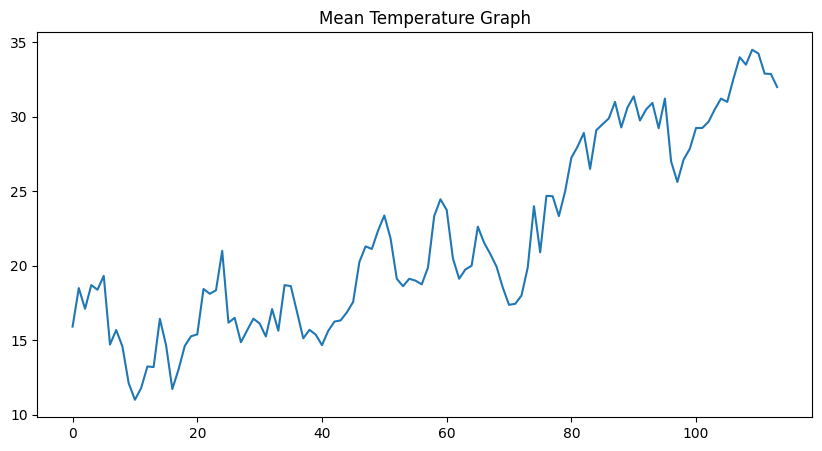

In [41]:
plt.figure(figsize=(10,5))
plt.plot(df['meantemp'])
plt.title('Mean Temperature Graph')
plt.show()

# Stationarity Check

In [42]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(df['meantemp'])
print('ADF Statistic:', result[0])
print('p-value:', result[1])

ADF Statistic: -1.096474275875619
p-value: 0.7164758731775932


# ARIMA Model

In [43]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(df['meantemp'], order = (1,1,1))
model_fit = model.fit()
forcast = model_fit.forecast(steps = 10)
print(forcast)

114    32.107680
115    32.094800
116    32.096340
117    32.096156
118    32.096178
119    32.096175
120    32.096176
121    32.096176
122    32.096176
123    32.096176
Name: predicted_mean, dtype: float64


# ARIMA Forecast Plot

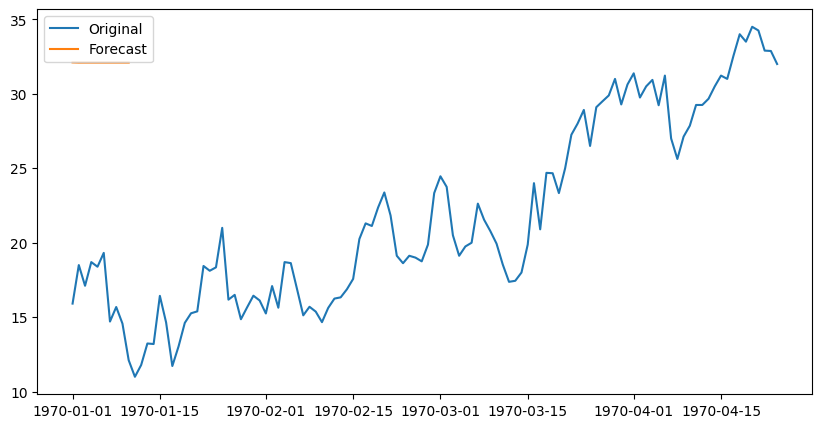

In [44]:
plt.figure(figsize=(10,5))

plt.plot(df['meantemp'], label='Original')

plt.plot(
    pd.date_range(df.index[-1], periods=10, freq='D'),
    forcast,
    label='Forecast'
)

plt.legend()
plt.show()

# SARIMA Model

In [45]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima = SARIMAX(
    df['meantemp'],
    order = (1,1,1),
    seasonal_order = (1,1,1,12)
)

sarima_fit = sarima.fit()
sarima_forcast = sarima_fit.forecast(steps = 10)
print(sarima_forcast)

114    31.640199
115    31.617368
116    32.113416
117    32.369843
118    33.111204
119    33.377108
120    33.496079
121    32.685284
122    33.832114
123    33.422522
Name: predicted_mean, dtype: float64


# Prophet Model

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


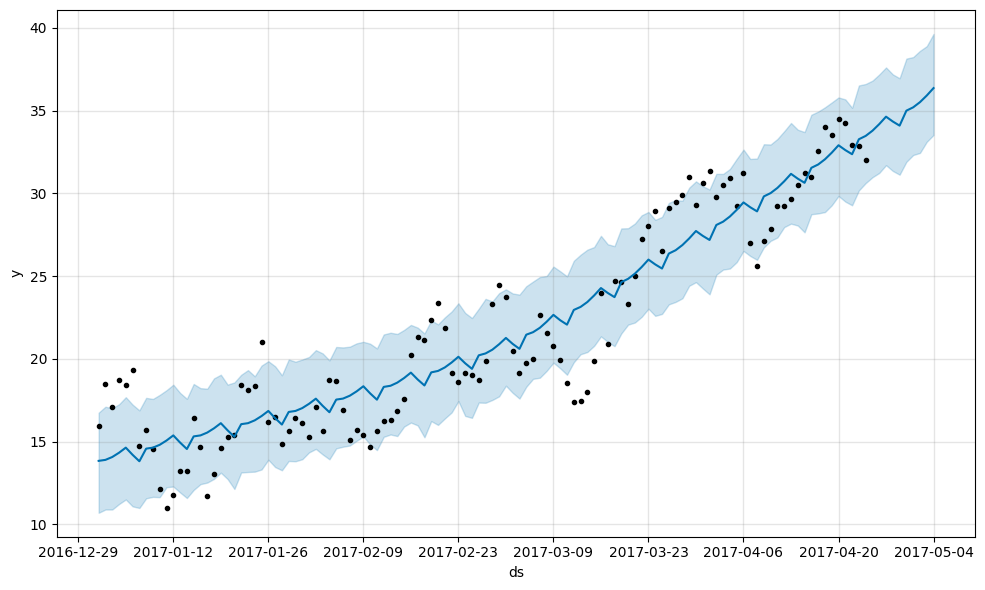

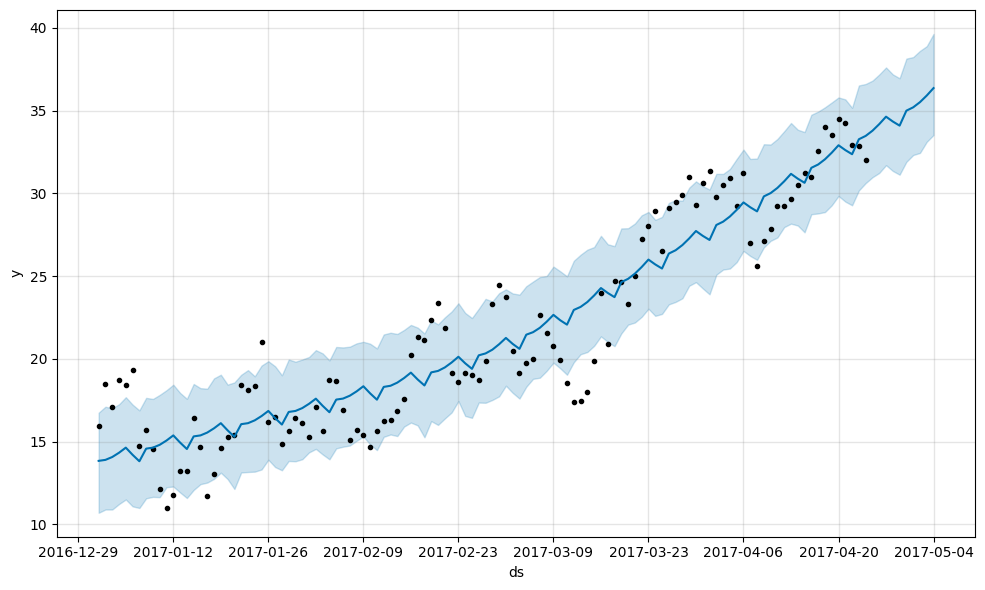

In [46]:
from prophet import Prophet

prophet_df = df.reset_index()[['date','meantemp']]
prophet_df.columns = ['ds','y']
model = Prophet()

model.fit(prophet_df)
future = model.make_future_dataframe(periods=10)

forecast = model.predict(future)

model.plot(forecast)


In [48]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Model Evaluation

In [49]:
from sklearn.metrics import mean_absolute_error

actual = df['meantemp'][-10:]
predicted = model_fit.predict(start=len(df)-10,end=len(df)-1)
mae = mean_absolute_error(actual,predicted)
print("MAE:",mae)

MAE: 0.7960280084727532


# Transfer Learning

## Extract Dataset

In [50]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
import matplotlib.pyplot as plt

In [51]:
import zipfile

zip_path = "/content/seg_train.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset")

print("Dataset Extracted Successfully")

Dataset Extracted Successfully


## Image Preprocessing

In [52]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = train_datagen.flow_from_directory(
    "/content/dataset/seg_train",
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = train_datagen.flow_from_directory(
    "/content/dataset/seg_train",
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.


## Load MobileNetV2

In [53]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

## Freeze Base Layers

In [54]:
base_model.trainable = False

## Build Transfer Learning Model

In [55]:
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(6, activation='softmax')
])

## Compile Model

In [56]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

## Train Model

In [57]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 339s 950ms/step - accuracy: 0.8688 - loss: 0.3605 - val_accuracy: 0.9048 - val_loss: 0.2660
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 332s 947ms/step - accuracy: 0.9103 - loss: 0.2530 - val_accuracy: 0.9108 - val_loss: 0.2484
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 332s 945ms/step - accuracy: 0.9220 - loss: 0.2143 - val_accuracy: 0.9037 - val_loss: 0.2590
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 353s 1s/step - accuracy: 0.9254 - loss: 0.1989 - val_accuracy: 0.9119 - val_loss: 0.2506
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 331s 943ms/step - accuracy: 0.9333 - loss: 0.1824 - val_accuracy: 0.9101 - val_loss: 0.2574


## Evaluate Model

In [ ]:
loss , accuracy = model.evaluate(val_data)
print("Loss:",loss)
print("Accuracy:",accuracy)

14/88 ━━━━━━━━━━━━━━━━━━━━ 57s 775ms/step - accuracy: 0.9142 - loss: 0.2662

## Accuracy Graph

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train','Validation'])

plt.show()

## Loss Graph

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train','Validation'])

plt.show()

## Conclusion

### Dataset Loading and Preprocessing
- The climate dataset was successfully loaded and preprocessed.
- The date column was converted into datetime format and the dataset was prepared for forecasting.

### ARIMA Model
- The ARIMA model was implemented as a baseline forecasting technique.
- Future temperature values were predicted using historical observations.

### SARIMA Model
- The SARIMA model was applied to capture seasonal patterns in the climate data.
- It improved forecasting performance by considering seasonality.

### Prophet Model
- The Prophet model was implemented for trend analysis and forecasting.
- It provided an efficient and flexible approach for time series prediction.

### Forecast Generation
- Forecasts were generated using ARIMA, SARIMA, and Prophet models.
- The predicted values were analyzed and compared.

### Model Evaluation
- Model performance was evaluated using the Mean Absolute Error (MAE) metric.
- The evaluation helped measure the accuracy of each forecasting model.

### Model Comparison
- The forecasting results of all models were compared.
- SARIMA and Prophet demonstrated better performance than ARIMA.

### Overall Outcome
- The project successfully applied time series forecasting techniques to real-world climate data.
- It provided practical experience in forecasting, model evaluation, and performance comparison.

## Transfer Learning Conclusion

### Data Preprocessing
- The image dataset was successfully loaded and preprocessed.
- All images were resized and normalized to prepare them for deep learning training.

### Transfer Learning
- MobileNetV2 was selected as the pre-trained convolutional neural network.
- Transfer learning enabled the model to leverage previously learned features from the ImageNet dataset.

### Freezing Base Layers
- The pre-trained base layers were frozen to preserve the learned feature representations.
- This reduced training time and improved computational efficiency.

### Model Building
- Custom classification layers were added on top of the MobileNetV2 architecture.
- The modified network was designed to perform image classification on the target dataset.

### Model Training
- The model was trained using the training dataset and validated using a separate validation set.
- Training was performed to optimize the model's ability to classify images accurately.

### Model Evaluation
- The trained model was evaluated using accuracy and loss metrics.
- The evaluation results demonstrated the effectiveness of transfer learning for image classification tasks.

### Accuracy and Loss Analysis
- Accuracy and loss curves were analyzed to assess model performance.
- The visualizations helped identify the learning behavior and generalization capability of the model.

### Overall Outcome
- Transfer learning with MobileNetV2 successfully improved image classification performance.
- The project provided practical experience in deep learning, transfer learning, and image classification using pre-trained CNN models.